# Marketing A/B Test Analysis: Did the Ad Campaign Work?

**Tools:** Python (pandas, NumPy, SciPy, statsmodels), SQL (SQLite), Matplotlib, Seaborn

**Data:** [Marketing A/B Testing (Kaggle)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing), 588,101 users




## 1. Business problem

**Context.** A marketing team spends budget on an online ad campaign. Looking only at how many ad viewers bought the product is misleading, because many of them would have bought anyway. To measure the true effect, the company ran an **A/B test**:

- **Treatment group ("ad"):** saw the company's ads.
- **Control group ("psa"):** saw a public service announcement in the exact same ad slot. They show us what happens without the ads.

Why show a public service announcement instead of nothing?
Because researchers want both groups to have the same experience of seeing something in the ad space.

The main difference is:
- One group sees the commercial advertisement.
- The other group does not see the commercial advertisement.

**The decision to support:** should the company keep paying for this campaign and how could it spend the budget better?

**Business questions**

1. Did the ads increase conversions and is the difference statistically significant? 
2. How many additional conversions did the ads generate? (incremental conversions)?
3. How many ads were needed to generate each additional conversion?
4. Where did the ads make the biggest difference (number of ads seen, day of week)?


**Success metric:** conversion rate = users who converted ÷ users in the group.

**Hypotheses** (significance level α = 0.05)

- **H₀:** the conversion rate is the same in the ad group and the PSA group.
- **H₁:** the conversion rate is different in the two groups.



## 2. The dataset

Each row is one user.


- `Unnamed: 0`  = dropped, row number, not useful 
- `user id` = Unique user identifier 
- `test group` = `ad` = saw the ads, `psa` = saw the public service announcement 
- `converted` = `True` if the user bought the product 
- `total ads` = Number of ads (or PSAs) the user saw 
- `most ads day` = Day of the week on which the user saw the most ads 
- `most ads hour` = Hour of the day (0 to 23) in which the user saw the most ads 

### 2.1 Setup

In [9]:
import math
import os
import sqlite3
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

warnings.filterwarnings('ignore', category=FutureWarning)


AD_COLOR, PSA_COLOR, GREY, INK = '#69516F', '#91A88C', '#D8D8CE', '#37343A'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.titlelocation': 'left',
    'grid.color': '#e8e7e3', 'grid.linewidth': 0.8,
})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)
DAYS = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

### 2.2 The dataset

In [10]:
raw = pd.read_csv('marketing_AB.csv')
print(f'Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}')
raw.head()

Rows: 588,101 | Columns: 7


,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [11]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


588,101 rows and 7 columns. Every column is fully filled in. The first column is just a row counter and the column names contain spaces, so I clean both in the next section.


## 3. Data quality checks and cleaning

Before any analysis I check the things that could break an A/B test: missing values, duplicate users, users who appear in both groups and impossible values.

In [12]:
quality = pd.DataFrame({
    'Check': ['Missing values', 'Fully duplicated rows', 'Duplicated user ids',
              'Group labels', 'Converted values', 'Users with 0 or negative ads',
              'Hours outside 0-23', 'Day names'],
    'Result': [raw.isna().sum().sum(), raw.duplicated().sum(), raw['user id'].duplicated().sum(),
               ', '.join(sorted(raw['test group'].unique())), ', '.join(map(str, sorted(raw['converted'].unique()))),
               (raw['total ads'] <= 0).sum(), (~raw['most ads hour'].between(0, 23)).sum(),
               f"{raw['most ads day'].nunique()} unique, all valid: {set(raw['most ads day']) == set(DAYS)}"],
})
quality

,Check,Result
0,Missing values,0
1,Fully duplicated rows,0
2,Duplicated user ids,0
3,Group labels,"ad, psa"
4,Converted values,"False, True"
5,Users with 0 or negative ads,0
6,Hours outside 0-23,0
7,Day names,"7 unique, all valid: True"


In [13]:
df = raw.drop(columns='Unnamed: 0').copy()
df.columns = ['user_id', 'group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']
df['converted'] = df['converted'].astype(int)                                   # True/False -> 1/0
df['most_ads_day'] = pd.Categorical(df['most_ads_day'], categories=DAYS, ordered=True)

print(f'Clean dataset: {df.shape[0]:,} rows, {df.shape[1]} columns')
df.head()

Clean dataset: 588,101 rows, 6 columns


,user_id,group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


The data is clean. There are no missing values, no duplicated users (so nobody is in both groups) and no impossible values. The only cleaning needed was dropping the row counter, renaming the columns, turning `converted` into 1/0 and putting the days in calendar order. No rows were removed.


## 4. Exploratory data analysis (EDA)

### 4.1 How big are the two groups?

In [14]:
group_summary = df.groupby('group').agg(users=('user_id', 'size'), conversions=('converted', 'sum'))
group_summary['share_of_users_pct'] = group_summary['users'] / len(df) * 100
group_summary['conversion_rate_pct'] = group_summary['conversions'] / group_summary['users'] * 100
print(f"Overall conversion rate: {df['converted'].mean():.2%}")
group_summary

Overall conversion rate: 2.52%


,users,conversions,share_of_users_pct,conversion_rate_pct
group,,,,
ad,564577,14423,96.00,2.55
psa,23524,420,4.00,1.79


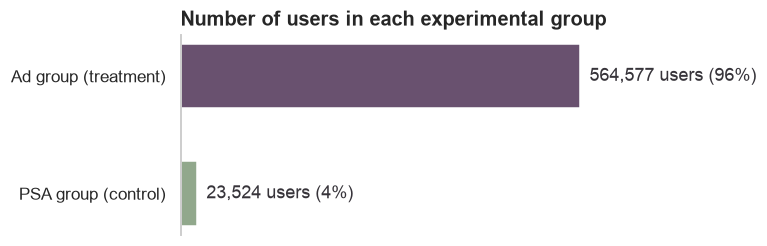

In [15]:
fig, ax = plt.subplots(figsize=(7, 2.4))
bars = ax.barh(['PSA group (control)', 'Ad group (treatment)'], group_summary.loc[['psa', 'ad'], 'users'],
               color=[PSA_COLOR, AD_COLOR], height=0.55)
ax.bar_label(bars, labels=[f"{group_summary.loc[g, 'users']:,} users ({group_summary.loc[g, 'share_of_users_pct']:.0f}%)"
                           for g in ['psa', 'ad']], padding=6, color=INK)
ax.set_xlim(0, 760_000); ax.xaxis.set_visible(False); ax.grid(False); ax.spines['bottom'].set_visible(False)
ax.set_title('Number of users in each experimental group')
plt.tight_layout(); plt.savefig('figures/01_group_sizes.png', bbox_inches='tight'); plt.show()

**Insight:** The group split is very uneven: 96% of users were assigned to the ad group and 4% to the PSA group. One possible business reason is that the company wanted to show its commercial ads to as many users as possible while maintaining a smaller control group for comparison.

The PSA group still contains 23,524 users, providing a substantial basis for comparison. However, because it is smaller than the ad group, its conversion rate is estimated with less precision. Conversion is also a relatively rare event: only 2.5% of all users converted.

### 4.2 How many ads did users see?

In [16]:
df['total_ads'].describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame().T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
total_ads,"588,101.00",24.82,43.72,1.00,4.00,13.00,27.00,57.00,88.00,202.00,"2,065.00"


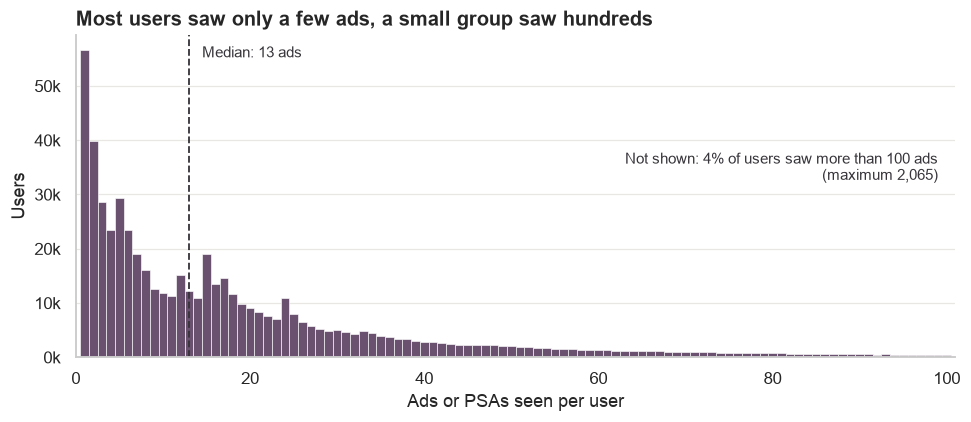

Users who saw more than 202 ads (1.0% of users) received 13% of all impressions.


In [18]:
median, p99 = df['total_ads'].median(), df['total_ads'].quantile(.99)
over_100 = (df['total_ads'] > 100).mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(df.loc[df['total_ads'] <= 100, 'total_ads'], bins=np.arange(0.5, 101.5, 1), color=AD_COLOR, edgecolor='white', linewidth=0.4)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v / 1000:,.0f}k'))
ax.axvline(median, color=INK, ls='--', lw=1.2)
ax.text(median + 1.5, ax.get_ylim()[1] * 0.93, f'Median: {median:.0f} ads', color=INK, fontsize=9.5)
ax.text(99, ax.get_ylim()[1] * 0.55, f"Not shown: {over_100:.0%} of users saw more than 100 ads\n(maximum {df['total_ads'].max():,})",
        color=INK, fontsize=9.5, ha='right')
ax.set_xlim(0, 101); ax.set_xlabel('Ads or PSAs seen per user'); ax.set_ylabel('Users'); ax.grid(axis='x', visible=False)
ax.set_title('Most users saw only a few ads, a small group saw hundreds')
plt.tight_layout(); plt.savefig('figures/02_ads_distribution.png', bbox_inches='tight'); plt.show()

heavy = df['total_ads'] > p99

print(
    f"Users who saw more than {p99:.0f} ads "
    f"({heavy.mean():.1%} of users) received "
    f"{df.loc[heavy, 'total_ads'].sum() / df['total_ads'].sum():.0%} "
    f"of all impressions."
)

**Insight:** The number of ads seen per user varies considerably. Half of all users saw 13 ads or fewer, while the average was 25. A small number of users saw much more advertising, with the highest exposure reaching 2,065 ads. The top 1% of users received 13% of all impressions.

The distribution is strongly right-skewed, meaning a small group of users accounts for a large share of total ad exposure. Therefore, the median and exposure groups are more useful than the average for describing typical user exposure. The histogram shows only users who saw up to 100 ads to keep the main distribution readable.

### 4.3 Do users who see more ads convert more often?

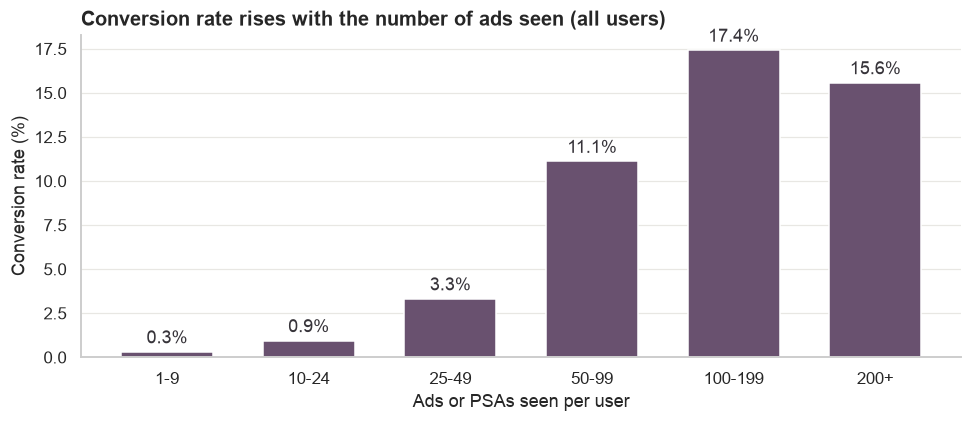

,users,conversion_rate_pct,share_of_users_pct
exposure,,,
1-9,248910,0.31,42.32
10-24,173223,0.95,29.45
25-49,94874,3.32,16.13
50-99,47625,11.12,8.10
100-199,17468,17.43,2.97
200+,6001,15.58,1.02


In [19]:
BANDS = ['1-9', '10-24', '25-49', '50-99', '100-199', '200+']
df['exposure'] = pd.cut(df['total_ads'], [0, 9, 24, 49, 99, 199, np.inf], labels=BANDS)

by_band = df.groupby('exposure', observed=True).agg(users=('user_id', 'size'), conversion_rate_pct=('converted', 'mean'))
by_band['conversion_rate_pct'] *= 100
by_band['share_of_users_pct'] = by_band['users'] / len(df) * 100

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(by_band.index, by_band['conversion_rate_pct'], color=AD_COLOR, width=0.65)
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in by_band['conversion_rate_pct']], padding=3, color=INK)
ax.set_xlabel('Ads or PSAs seen per user'); ax.set_ylabel('Conversion rate (%)'); ax.grid(axis='x', visible=False)
ax.set_title('Conversion rate rises with the number of ads seen (all users)')
plt.tight_layout(); plt.savefig('figures/03_conversion_by_exposure.png', bbox_inches='tight'); plt.show()
by_band

**Insight:** conversion goes from 0.3% for users with fewer than 10 ads to about 17% for users with 100 to 199 ads, then flattens.

**This is correlation, not proof that more ads cause more sales.** People who browse a lot see more ads *and* are more likely to buy anyway. The PSA group helps here: in section 7 I compare ad users with PSA users who had the same exposure, which removes most of this "active user" effect.

### 4.4 When do users convert? Day of week and hour of day

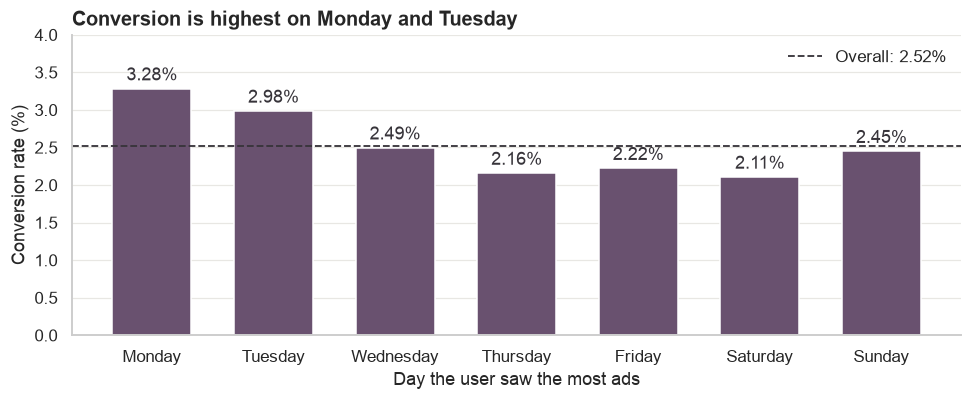

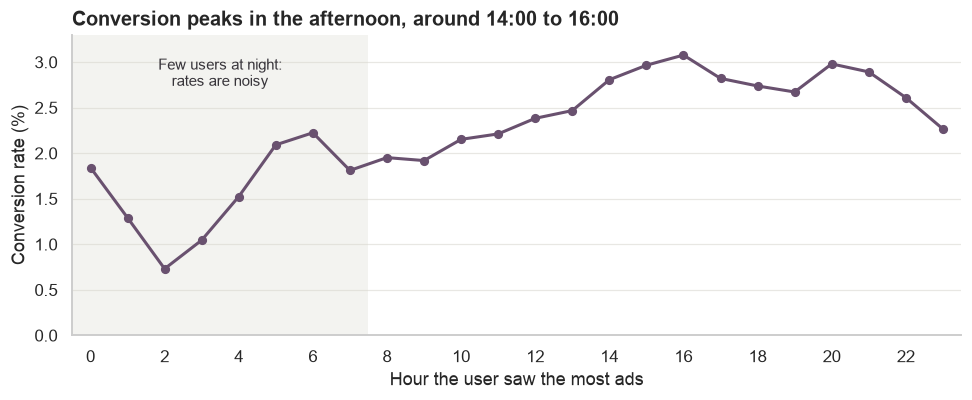

Users whose top hour is between 00:00 and 07:59: 4.8%


In [20]:
by_day_all = df.groupby('most_ads_day', observed=True)['converted'].agg(['mean', 'size'])
by_hour_all = df.groupby('most_ads_hour')['converted'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(by_day_all.index, by_day_all['mean'] * 100, color=AD_COLOR, width=0.65)
ax.bar_label(bars, labels=[f'{v:.2%}' for v in by_day_all['mean']], padding=3, color=INK)
ax.axhline(df['converted'].mean() * 100, color=INK, ls='--', lw=1.2, label=f"Overall: {df['converted'].mean():.2%}")
ax.legend(loc='upper right', frameon=False); ax.set_ylim(0, 4)
ax.set_ylabel('Conversion rate (%)'); ax.set_xlabel('Day the user saw the most ads'); ax.grid(axis='x', visible=False)
ax.set_title('Conversion is highest on Monday and Tuesday')
plt.tight_layout(); plt.savefig('figures/04_conversion_by_day.png', bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(by_hour_all.index, by_hour_all['mean'] * 100, color=AD_COLOR, lw=2, marker='o', ms=5)
ax.axvspan(-0.5, 7.5, color=GREY, alpha=0.3, lw=0)
ax.text(3.5, 3.05, 'Few users at night:\nrates are noisy', ha='center', va='top', color=INK, fontsize=9.5)
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(0, 3.3)
ax.set_ylabel('Conversion rate (%)'); ax.set_xlabel('Hour the user saw the most ads'); ax.grid(axis='x', visible=False)
ax.set_title('Conversion peaks in the afternoon, around 14:00 to 16:00')
plt.tight_layout(); plt.savefig('figures/05_conversion_by_hour.png', bbox_inches='tight'); plt.show()

print(f"Users whose top hour is between 00:00 and 07:59: {by_hour_all.loc[0:7, 'size'].sum() / len(df):.1%}")

**Insight:**
- **Day:** users who saw most of their ads on Monday (3.28%) or Tuesday (2.98%) convert most, Saturday is lowest (2.11%).
- **Hour:** conversion climbs through the day and peaks at 16:00 (3.08%). It is lowest in the early morning, but fewer than 5% of users fall in the 00:00 to 07:59 window, so those rates are noisy.

These columns describe *when the user was most exposed*, not when they bought and they were not randomly assigned. They are useful as ideas for ad scheduling tests, not as proof.

### 4.5 Are the two groups comparable?

An A/B test is only fair if the groups are similar apart from the ad. The dataset has few user attributes, but I can compare how many ads or PSAs each group saw and when.

In [21]:
balance = df.groupby('group')['total_ads'].agg(mean_ads='mean', median_ads='median', p90_ads=lambda s: s.quantile(.9))
display(balance)

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table)[0]
    return math.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

print(f"Cramér's V, group vs day:  {cramers_v(df['most_ads_day'], df['group']):.3f}")
print(f"Cramér's V, group vs hour: {cramers_v(df['most_ads_hour'], df['group']):.3f}")
print('(0 = no relationship, 1 = perfect relationship; below 0.1 is negligible)')

,mean_ads,median_ads,p90_ads
group,,,
ad,24.82,13.00,56.00
psa,24.76,12.00,59.00


Cramér's V, group vs day:  0.020
Cramér's V, group vs hour: 0.018
(0 = no relationship, 1 = perfect relationship; below 0.1 is negligible)


**Insight:** both groups saw almost the same number of ads or PSAs (mean 24.8 in both, median 13 vs 12). The day and hour mix differs very slightly between groups (Cramér's V around 0.02). So the groups look comparable and I double-check in section 7 that the day mix doesn't change the result.


## 5. A/B test: did the ads increase conversions?

### 5.1 Conversion rate per group (SQL)

I load the table into an in-memory SQLite database to show the same summary a business analyst would pull from a data warehouse.

In [22]:
conn = sqlite3.connect(':memory:')
df.drop(columns='exposure').astype({'most_ads_day': str}).to_sql('users', conn, index=False)

results = pd.read_sql_query('''
SELECT  "group",
        COUNT(*)                         AS users,
        SUM(converted)                   AS conversions,
        ROUND(100.0 * AVG(converted), 2) AS conversion_rate_pct
FROM    users
GROUP BY "group"
''', conn).set_index('group')
results

,users,conversions,conversion_rate_pct
group,,,
ad,564577,14423,2.55
psa,23524,420,1.79


### 5.2 Statistical test

The outcome is yes/no (converted or not) and the two groups are independent and large, so the right tool is a **two-proportion z-test**. I also run a **chi-square test** as a cross-check and compute a **95% confidence interval** for the difference, because the size of the effect matters more to the business than the p-value.

In [23]:
ad_n, ad_c = int(results.loc['ad', 'users']), int(results.loc['ad', 'conversions'])
psa_n, psa_c = int(results.loc['psa', 'users']), int(results.loc['psa', 'conversions'])
ad_rate, psa_rate = ad_c / ad_n, psa_c / psa_n

# Two-proportion z-test and chi-square test
z_stat, p_value = proportions_ztest([ad_c, psa_c], [ad_n, psa_n])
chi2, p_chi2, _, _ = stats.chi2_contingency(pd.crosstab(df['group'], df['converted']), correction=False)

# 95% confidence interval for the absolute difference
difference = ad_rate - psa_rate
se = math.sqrt(ad_rate * (1 - ad_rate) / ad_n + psa_rate * (1 - psa_rate) / psa_n)
margin = 1.96 * se
ci_low, ci_high = difference - margin, difference + margin

# 95% confidence interval for the relative lift (on the log scale)
ratio = ad_rate / psa_rate
se_log = math.sqrt((1 - ad_rate) / ad_c + (1 - psa_rate) / psa_c)
rel_low, rel_high = math.exp(math.log(ratio) - 1.96 * se_log) - 1, math.exp(math.log(ratio) + 1.96 * se_log) - 1

print(f'Ad group conversion rate:   {ad_rate:.2%}')
print(f'PSA group conversion rate:  {psa_rate:.2%}')
print(f'Absolute difference:        {difference * 100:.2f} percentage points (95% CI {ci_low * 100:.2f} to {ci_high * 100:.2f})')
print(f'Relative lift:              {ratio - 1:.0%} (95% CI {rel_low:.0%} to {rel_high:.0%})')
print(f'z-test:                     z = {z_stat:.2f}, p = {p_value:.1e}')
print(f'Chi-square test:            chi2 = {chi2:.1f}, p = {p_chi2:.1e}')
print(f"Decision at alpha = 0.05:   {'reject H0, the rates differ' if p_value < 0.05 else 'cannot reject H0'}")

Ad group conversion rate:   2.55%
PSA group conversion rate:  1.79%
Absolute difference:        0.77 percentage points (95% CI 0.60 to 0.94)
Relative lift:              43% (95% CI 30% to 58%)
z-test:                     z = 7.37, p = 1.7e-13
Chi-square test:            chi2 = 54.3, p = 1.7e-13
Decision at alpha = 0.05:   reject H0, the rates differ


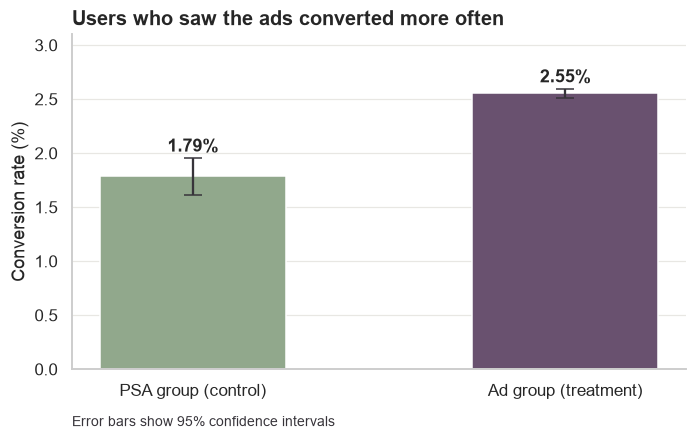

In [24]:
rates = np.array([psa_rate, ad_rate]) * 100
errors = 196 * np.sqrt([psa_rate * (1 - psa_rate) / psa_n, ad_rate * (1 - ad_rate) / ad_n])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(['PSA group (control)', 'Ad group (treatment)'], rates, yerr=errors, capsize=6,
              color=[PSA_COLOR, AD_COLOR], ecolor=INK, width=0.5)
for i, (r, e) in enumerate(zip(rates, errors)):
    ax.text(i, r + e + 0.06, f'{r:.2f}%', ha='center', fontweight='bold')
ax.set_ylabel('Conversion rate (%)'); ax.set_ylim(0, 3.1); ax.grid(axis='x', visible=False)
ax.set_title('Users who saw the ads converted more often')
ax.text(0, -0.17, 'Error bars show 95% confidence intervals', transform=ax.transAxes, color=INK, fontsize=9)
plt.tight_layout(); plt.savefig('figures/06_conversion_rate_ab.png', bbox_inches='tight'); plt.show()

**Insight:** yes, the ads worked.

- The ad group converted at **2.55%** and the PSA group at **1.79%**.
- The difference is **0.77 percentage points** (95% CI 0.60 to 0.94), a **43% absolute lift** (95% CI 30% to 58%).
- The p-value is far below 0.05 in both tests (z = 7.37), so I reject H₀. A gap this large is extremely unlikely to be chance.
- The confidence intervals of the two groups do not overlap and the PSA group's interval is wider because that group is smaller.

### 5.3 Robustness checks

Two quick checks that the result doesn't depend on the method:

1. **Simulation (parametric bootstrap):** redraw both groups 10,000 times from their observed rates and look at the spread of the difference. This does not rely on the normal-approximation formula.
2. **Sensitivity:** with a control group of only 4%, what is the smallest lift this test could reliably detect (80% power)?

In [25]:
rng = np.random.default_rng(42)
sim_diff = rng.binomial(ad_n, ad_rate, 10_000) / ad_n - rng.binomial(psa_n, psa_rate, 10_000) / psa_n
boot_low, boot_high = np.percentile(sim_diff, [2.5, 97.5])
print(f'Simulated 95% interval for the difference: {boot_low * 100:.2f} to {boot_high * 100:.2f} percentage points')
print(f'Formula-based 95% interval:                {ci_low * 100:.2f} to {ci_high * 100:.2f} percentage points')
print(f'Simulations where the ad group did not win: {(sim_diff <= 0).mean():.2%}')

# Minimum detectable effect at alpha = 0.05 (two-sided) and 80% power
mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
print(f'\nSmallest lift the test could reliably detect: {mde * 100:.2f} percentage points')
print(f'Observed lift: {difference * 100:.2f} percentage points ({difference / mde:.1f}x larger)')

Simulated 95% interval for the difference: 0.60 to 0.94 percentage points
Formula-based 95% interval:                0.60 to 0.94 percentage points
Simulations where the ad group did not win: 0.00%

Smallest lift the test could reliably detect: 0.25 percentage points
Observed lift: 0.77 percentage points (3.1x larger)


**Insight:** the simulation gives the same interval as the formula (0.60 to 0.94 points) and the ad group wins in every simulated run. The test was sensitive enough to detect a lift of about 0.25 points and the observed lift is three times larger. The small control group is therefore not a concern for the headline result.

## 6. Business impact: what did the ads really add?

### 6.1 Incremental conversions

The ad group had 14,423 conversions but not all of them were caused by ads. The PSA group shows how many would have happened anyway:

 **extra conversions = ad group conversions − (PSA conversion rate × ad group users)**

Total conversions in the ad group:  14,423
Would likely have happened anyway:  10,080 (70%)
Extra conversions from the ads:     4,343 (30%), 95% CI 3,360 to 5,326


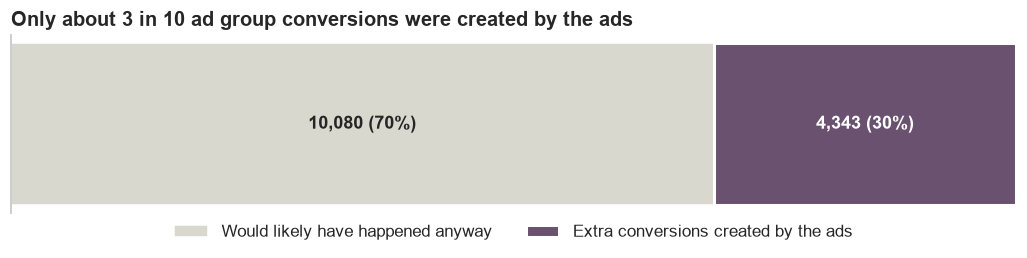

In [26]:
anyway = psa_rate * ad_n
extra = ad_c - anyway
extra_low, extra_high = ci_low * ad_n, ci_high * ad_n

print(f'Total conversions in the ad group:  {ad_c:,.0f}')
print(f'Would likely have happened anyway:  {anyway:,.0f} ({anyway / ad_c:.0%})')
print(f'Extra conversions from the ads:     {extra:,.0f} ({extra / ad_c:.0%}), 95% CI {extra_low:,.0f} to {extra_high:,.0f}')

fig, ax = plt.subplots(figsize=(9.5, 2.5))
ax.barh([''], [anyway], color=GREY, height=0.6, label='Would likely have happened anyway')
ax.barh([''], [extra], left=[anyway], color=AD_COLOR, height=0.6, edgecolor='white', linewidth=2, label='Extra conversions created by the ads')
ax.text(anyway / 2, 0, f'{anyway:,.0f} ({anyway / ad_c:.0%})', ha='center', va='center', fontweight='bold')
ax.text(anyway + extra / 2, 0, f'{extra:,.0f} ({extra / ad_c:.0%})', ha='center', va='center', fontweight='bold', color='white')
ax.set_xlim(0, ad_c); ax.grid(False); ax.xaxis.set_visible(False); ax.spines['bottom'].set_visible(False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2, frameon=False)
ax.set_title('Only about 3 in 10 ad group conversions were created by the ads')
plt.tight_layout(); plt.savefig('figures/07_incremental_conversions.png', bbox_inches='tight'); plt.show()

**Insight:** counting all 14,423 conversions would overstate the campaign by more than three times. About 10,080 (70%) would likely have happened anyway. The ads created about **4,343 extra conversions** (95% CI 3,360 to 5,326). This incremental number is the one the campaign should be judged on.

### 6.2 How much advertising does one extra conversion take?

The dataset has no cost or revenue columns, so I cannot calculate profit or ROI. What I can calculate is the number of impressions per extra conversion and then show what that would cost at a few **example** prices per 1,000 impressions (CPM). The prices are illustrations, not real figures.

In [27]:
ads_shown = df.loc[df['group'] == 'ad', 'total_ads'].sum()
ads_per_extra = ads_shown / extra
print(f'Ad impressions shown to the ad group: {ads_shown:,.0f}')
print(f'Impressions per extra conversion:     {ads_per_extra:,.0f} '
      f'(95% CI {ads_shown / extra_high:,.0f} to {ads_shown / extra_low:,.0f})')

cost_scenarios = pd.DataFrame({
    'Example CPM (cost per 1,000 ads)': ['$1', '$5', '$10'],
    'Campaign cost': [f'${ads_shown / 1000 * cpm:,.0f}' for cpm in (1, 5, 10)],
    'Cost per extra conversion': [f'${ads_per_extra / 1000 * cpm:,.2f}' for cpm in (1, 5, 10)],
})
cost_scenarios

Ad impressions shown to the ad group: 14,014,701
Impressions per extra conversion:     3,227 (95% CI 2,631 to 4,171)


,"Example CPM (cost per 1,000 ads)",Campaign cost,Cost per extra conversion
0,$1,"$14,015",$3.23
1,$5,"$70,074",$16.13
2,$10,"$140,147",$32.27


**Insight:** each extra conversion took about **3,227 impressions** (95% CI about 2,600 to 4,200). At an example CPM of 5 that is about 16 per extra conversion.

**Decision rule:** the campaign pays off if the profit from one extra conversion is higher than the cost of about 3,200 impressions. The marketing team can plug in its real CPM and margin.


## 7. Where did the ads make the biggest difference?

### 7.1 Lift by number of ads seen

In section 4.3 conversion rose with exposure, but active users both see more ads and buy more. To separate the two, I compare ad users with PSA users **inside the same exposure band**. The difference between them is the lift at that level of exposure.

In [28]:
df[['user_id', 'exposure']].astype({'exposure': str}).to_sql('exposure_bands', conn, index=False)

t = pd.read_sql_query('''
SELECT  e.exposure,
        SUM(CASE WHEN u."group" = 'ad'  THEN 1 ELSE 0 END)           AS ad_users,
        SUM(CASE WHEN u."group" = 'psa' THEN 1 ELSE 0 END)           AS psa_users,
        SUM(CASE WHEN u."group" = 'ad'  THEN u.converted ELSE 0 END) AS ad_conversions,
        SUM(CASE WHEN u."group" = 'psa' THEN u.converted ELSE 0 END) AS psa_conversions,
        SUM(CASE WHEN u."group" = 'ad'  THEN u.total_ads ELSE 0 END) AS ads_shown
FROM    users u
JOIN    exposure_bands e ON u.user_id = e.user_id
GROUP BY e.exposure
''', conn).set_index('exposure').loc[BANDS]

t['ad_rate'] = t['ad_conversions'] / t['ad_users'] * 100
t['psa_rate'] = t['psa_conversions'] / t['psa_users'] * 100
t['lift_points'] = t['ad_rate'] - t['psa_rate']
t['margin'] = 196 * np.sqrt(t['ad_rate'] / 100 * (1 - t['ad_rate'] / 100) / t['ad_users']
                            + t['psa_rate'] / 100 * (1 - t['psa_rate'] / 100) / t['psa_users'])
t['extra_conversions'] = t['lift_points'] / 100 * t['ad_users']
t['share_of_ad_users_pct'] = t['ad_users'] / t['ad_users'].sum() * 100
t['share_of_ads_pct'] = t['ads_shown'] / t['ads_shown'].sum() * 100
t[['ad_users', 'psa_users', 'ad_rate', 'psa_rate', 'lift_points', 'margin', 'extra_conversions',
   'share_of_ad_users_pct', 'share_of_ads_pct']]

,ad_users,psa_users,ad_rate,psa_rate,lift_points,margin,extra_conversions,share_of_ad_users_pct,share_of_ads_pct
exposure,,,,,,,,,
1-9,238066,10844,0.31,0.38,-0.07,0.12,-161.10,42.17,6.68
10-24,167070,6153,0.95,0.99,-0.05,0.25,-76.31,29.59,19.47
25-49,91293,3581,3.35,2.51,0.84,0.53,763.57,16.17,22.35
50-99,45709,1916,11.35,5.53,5.82,1.06,"2,660.21",8.10,22.27
100-199,16699,769,17.74,10.53,7.21,2.25,"1,204.07",2.96,15.98
200+,5740,261,15.57,15.71,-0.13,4.51,-7.69,1.02,13.25


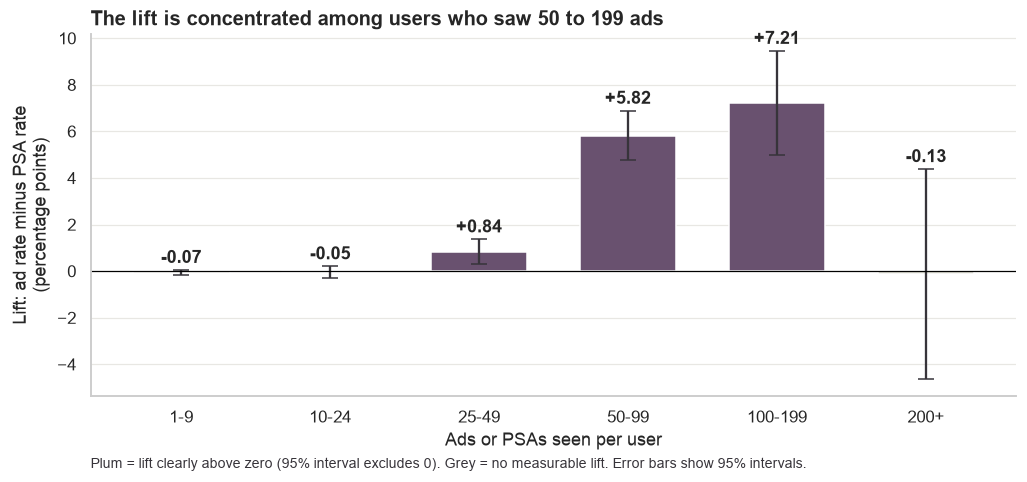

50-199 ads: 3,864 of 4,383 estimated extra conversions (88%), from 11% of ad users and 38% of ads
Under 25 ads: 72% of ad users, 26% of ads, no measurable lift
200+ ads: 1.0% of ad users, 13% of ads, no measurable lift
Impressions beyond each user's 200th: 5% of all ad impressions


In [37]:
clear = (t['lift_points'] - t['margin']) > 0          # whole 95% interval above zero
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.bar(t.index, t['lift_points'], yerr=t['margin'], capsize=5, ecolor=INK, width=0.65,
       color=[AD_COLOR if c else GREY for c in clear])
for i, (v, m) in enumerate(zip(t['lift_points'], t['margin'])):
    ax.text(i, v + m + 0.3, f'{v:+.2f}', ha='center', fontweight='bold')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Ads or PSAs seen per user'); ax.set_ylabel('Lift: ad rate minus PSA rate\n(percentage points)')
ax.grid(axis='x', visible=False)
ax.set_title('The lift is concentrated among users who saw 50 to 199 ads')
ax.text(0, -0.2, 'Plum = lift clearly above zero (95% interval excludes 0). Grey = no measurable lift. Error bars show 95% intervals.',
        transform=ax.transAxes, color=INK, fontsize=9)
plt.tight_layout(); plt.savefig('figures/08_lift_by_exposure.png', bbox_inches='tight'); plt.show()

total_extra = t['extra_conversions'].sum()
mid = t.loc[['50-99', '100-199']]
low = t.loc[['1-9', '10-24']]
print(f"50-199 ads: {mid['extra_conversions'].sum():,.0f} of {total_extra:,.0f} estimated extra conversions "
      f"({mid['extra_conversions'].sum() / total_extra:.0%}), from {mid['share_of_ad_users_pct'].sum():.0f}% of ad users and {mid['share_of_ads_pct'].sum():.0f}% of ads")
print(f"Under 25 ads: {low['share_of_ad_users_pct'].sum():.0f}% of ad users, {low['share_of_ads_pct'].sum():.0f}% of ads, no measurable lift")
print(f"200+ ads: {t.loc['200+', 'share_of_ad_users_pct']:.1f}% of ad users, {t.loc['200+', 'share_of_ads_pct']:.0f}% of ads, no measurable lift")

ad_ads = df.loc[df['group'] == 'ad', 'total_ads']
print(f"Impressions beyond each user's 200th: {(ad_ads - 200).clip(lower=0).sum() / ad_ads.sum():.0%} of all ad impressions")

**Insight:**
- **Under 25 ads:** no measurable lift. This group represents 72% of the ad group and accounts for 26% of all impressions.
- **25 to 49 ads:** A small but statistically significant positive lift of 0.84 percentage points.
- **50 to 199 ads:** The strongest positive lift, at 5.8 and 7.2 percentage points. Together these groups account for approximately 88% of estimated additional conversions, while representing only 11% of ad users and 38% of impressions.
- **200 or more ads:** No statistically significant positive lift was observed. However, the estimate is uncertain because only 261 PSA users fall into this exposure band. The highest-exposure 1% of users received 13% of all impressions and impressions beyond each user's 200th ad accounted for approximately 5% of total impressions.

**Limitation:** Only assignment to the ad or PSA group was randomised. The number of ads each user saw wasn't randomly assigned and may also be influenced by user behavior. For example, a user who purchases a product may stop seeing ads. Therefore, these results show where further testing may be useful, but they do not prove that a particular number of ads causes more conversions.

### 7.2 Does the result hold on every day of the week?

The day mix differs slightly between the groups (section 4.5), so I check that the overall lift is not created by that difference.

In [38]:
by_day = df.pivot_table(index='most_ads_day', columns='group', values='converted', aggfunc=['mean', 'size'], observed=True)
by_day.columns = ['ad_rate', 'psa_rate', 'ad_users', 'psa_users']
by_day[['ad_rate', 'psa_rate']] *= 100
by_day['lift_points'] = by_day['ad_rate'] - by_day['psa_rate']
by_day['margin'] = 196 * np.sqrt(by_day['ad_rate'] / 100 * (1 - by_day['ad_rate'] / 100) / by_day['ad_users']
                                 + by_day['psa_rate'] / 100 * (1 - by_day['psa_rate'] / 100) / by_day['psa_users'])

weights = (by_day['ad_users'] + by_day['psa_users']) / len(df)
adjusted = (weights * by_day['lift_points']).sum()
print(f'Lift after adjusting for the day mix: {adjusted:.2f} points (unadjusted: {difference * 100:.2f})')
print(f"Days where the ad group converted more: {(by_day['lift_points'] > 0).sum()} of 7")
by_day

Lift after adjusting for the day mix: 0.78 points (unadjusted: 0.77)
Days where the ad group converted more: 7 of 7


,ad_rate,psa_rate,ad_users,psa_users,lift_points,margin
most_ads_day,,,,,,
Monday,3.32,2.26,83571,3502,1.07,0.51
Tuesday,3.04,1.44,74572,2907,1.60,0.45
Wednesday,2.54,1.58,77418,3490,0.96,0.43
Thursday,2.16,2.02,79077,3905,0.14,0.45
Friday,2.25,1.63,88805,3803,0.62,0.41
Saturday,2.13,1.40,78802,2858,0.73,0.44
Sunday,2.46,2.06,82332,3059,0.40,0.51


**Insight:** the ad group converts more on all 7 days and the day-adjusted lift (0.78 points) is the same as the headline result (0.77). The lift looks larger on Tuesday (+1.60) and smaller on Thursday (+0.14), but each day has only about 3,000 to 4,000 PSA users, so the daily intervals are wide (about ±0.5 points) and seven comparisons will always show some spread by chance. I would not move budget between days based on this alone.

### 7.3 Outputs

In [39]:
summary = pd.DataFrame({
    'metric': ['ad_users', 'psa_users', 'ad_conversion_rate_pct', 'psa_conversion_rate_pct',
               'lift_points', 'lift_ci_low', 'lift_ci_high', 'relative_lift_pct', 'p_value',
               'extra_conversions', 'ads_per_extra_conversion'],
    'value': [ad_n, psa_n, ad_rate * 100, psa_rate * 100, difference * 100, ci_low * 100, ci_high * 100,
              (ratio - 1) * 100, p_value, extra, ads_per_extra],
})
summary.to_csv('outputs/ab_test_summary.csv', index=False)
t.reset_index().round(3).to_csv('outputs/lift_by_exposure.csv', index=False)
by_day.reset_index().round(3).to_csv('outputs/lift_by_day.csv', index=False)
conn.close()
print('Saved tables:', sorted(os.listdir('outputs')))
print('Saved charts:', sorted(os.listdir('figures')))

Saved tables: ['ab_test_summary.csv', 'lift_by_day.csv', 'lift_by_exposure.csv']
Saved charts: ['01_group_sizes.png', '02_ads_distribution.png', '03_conversion_by_exposure.png', '04_conversion_by_day.png', '05_conversion_by_hour.png', '06_conversion_rate_ab.png', '07_incremental_conversions.png', '08_lift_by_exposure.png']



## 8. Conclusions and recommendations

### Answers to the business questions

| # | Question | Answer |
|---|---|---|
| 1 | Did the ads increase conversions? | **Yes.** 2.55% vs 1.79%, +0.77 points (95% CI 0.60 to 0.94), 43% relative lift, p < 0.001 |
| 2 | How many conversions did the ads create? | About **4,343** (95% CI 3,360 to 5,326), which is 30% of the ad group's conversions |
| 3 | How much advertising per extra conversion? | About **3,227 impressions** |
| 4 | Where is the effect? | Among users with **50 to 199 ads** (about 88% of extra conversions). No measurable lift under 25 ads or above 200 ads |

### Recommendations

- Check whether the campaign makes money. The company should continue advertising only if the extra purchases generated by the ads are worth more than the advertising cost.
- Count only the extra purchases generated by advertising. Not everyone who saw an ad bought the product because of that ad. Some would have purchased anyway. The company should measure the additional purchases, not all purchases.
- Keep a control group. Continue showing PSAs to a small group of users. This helps the company compare what happens with and without commercial advertising.
- Test limiting the number of ads to 200 per user. Some users see hundreds of ads, but my analysis didn't find a clear increase in purchases in the 200+ group. The company could test whether showing fewer ads saves money without reducing purchases.
- Test showing more ads to users who see very few. My analysis found the strongest lift among users who saw 50–199 ads. The company could run an experiment to see whether increasing exposure for people who currently see fewer than 25 ads leads to more purchases.


## 9. Limitations and next steps

**Limitations**

- **No cost or revenue data:** I can measure extra conversions but not profit or ROI. The cost figures are examples.
- **Only the group was randomised:** the overall lift (sections 5 and 6) is the strongest result. The breakdowns by exposure, day and hour are observational and suggest what to test, not what is proven.
- **Small control group:** 4% is enough for the headline result but makes segment-level estimates (for example 200+ ads or single days) imprecise.
- **Missing context:** the data does not say what the product is, what counts as a conversion, when the campaign ran or how users were assigned. Because the planned split is unknown, I cannot run a sample-ratio check.
- **Ads vs PSA, not ads vs nothing:** the control group still saw something in the ad slot.
- **Public dataset:** I cannot independently confirm how the experiment was run.

**Next steps**

1. Cost per impression and revenue per conversion to calculate ROI.
2. Frequency cap test (recommendation 4) as a properly randomised experiment.
3. Larger control group (for example 10%) in the next test so segment results are more precise.
4. Conversion timestamp to study how long after exposure users convert.
